# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Agbay, Tristan Michael
- _Student No._: 2024-00281
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Error vs n for y1](./11-error-1.png)
![Error vs n for y2](./11-error-2.png)
![Error vs n for y3](./11-error-3.png)

**Figures 1-3.** Absolute error of each method compared with `scipy.integrate.quad`, plotted against the number of intervals (points for Monte Carlo) on log-log axes. Left to right: $y_1 = \sqrt{9-4x^2}$, $y_2 = -x^2+1$, $y_3 = \sqrt{x}\cos x$. For $y_2$, Simpson errors that are exactly 0 are drawn at $10^{-17}$ so they show on the log axis.

<img src="11-mc-1.png" alt="Monte Carlo points for y1" width=32%> <img src="11-mc-2.png" alt="Monte Carlo points for y2" width=32%> <img src="11-mc-3.png" alt="Monte Carlo points for y3" width=32%>

**Figures 4-6.** Monte Carlo points (5000 per curve) that land between the curve and the x-axis. Blue points are above the x-axis and red points are below it. Left to right: $y_1$, $y_2$, $y_3$. The title of each plot gives the signed integral and the total area from the points.

### Report discussion

**Explain the figures.**

Figures 1-3: Monte Carlo error is noisy and falls slowly, about as $1/\sqrt{n}$. Newton-Cotes errors are straight lines on the log-log plot, so they follow a power of $n$. For $y_2$, the trapezoid error drops as $n^{-2}$ while both Simpson rules sit at about $10^{-16}$, because Simpson's rules are exact for polynomials up to degree 3. For $y_1$ and $y_3$ all three rules drop only as $n^{-1.5}$, because the square root has an infinite slope at one end ($x=3/2$ for $y_1$, $x=0$ for $y_3$).

Figures 4-6: The integral is the blue area minus the red area, and the total area is blue plus red. $y_1$ is fully above the x-axis, so all its points are blue. $y_2$ is blue for $-1<x<1$ and red outside, and $y_3$ changes sign at $x=\pi/2$. All estimates are within about 5% of `quad`.

**Why does Monte Carlo work? When are Newton-Cotes methods better?**

An integral is $(b-a)$ times the average value of $f$ on $[a,b]$. If we pick random $x$ values and average $f$ at those points, the average gets closer to the true one as we add points (law of large numbers), with error that goes as $1/\sqrt{N}$. The same idea works for the hit-or-miss plots: the fraction of points inside the region times the box area gives the area.

Newton-Cotes methods are better when the integrand is smooth and the integral is in one or two dimensions. Their error drops much faster ($n^{-2}$ for trapezoid, $n^{-4}$ for Simpson), they give the same answer every run, and Simpson is exact for low-degree polynomials. Monte Carlo is better when there are many dimensions, since a grid needs $n^d$ points, or when the region is irregular.

### Other comments
- Monte Carlo curves change if the random seed changes, but the $1/\sqrt{n}$ trend stays.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



Test functions and the curves with their bounds. The `tests` list is reused by every later cell.

In [2]:
# integrands
def y1(x):
    return np.sqrt(9 - 4*x**2)

def y2(x):
    return -x**2 + 1

def y3(x):
    return np.sqrt(x)*np.cos(x)

# (function, lower bound, upper bound, label)
tests = [(y1, 0, 1.5, "y = sqrt(9 - 4x^2)"),
         (y2, -2, 2, "y = -x^2 + 1"),
         (y3, 0, np.pi, "y = sqrt(x) cos(x)")]

**Integration functions.** Each function takes `f`, the bounds `a`, `b` and the number of intervals (points for Monte Carlo) `n`, and returns the signed integral and the total area.
- Total area: do the same sum again on $|f(x)|$.
- Trapezoid: weights $\tfrac12, 1, 1, \dots, 1, \tfrac12$, times $h$.
- Simpson 1/3: weights $1, 4, 2, 4, \dots, 4, 1$, times $h/3$. Needs an even $n$.
- Simpson 3/8: weights $1, 3, 3, 2, 3, 3, 2, \dots, 3, 1$, times $3h/8$. Needs $n$ to be a multiple of 3.
- Monte Carlo: $(b-a)\times$ the average of $f$ at $n$ random points in $[a,b]$.
- Sums use NumPy slices instead of loops.

In [3]:
# All four functions return (signed integral, total area).
# The total area is found by doing the same sum on |f(x)|.
# n is the number of intervals, so there are n + 1 points with spacing h.

def trapezoid(f, a, b, n):
    h = (b - a)/n
    y = f(np.linspace(a, b, n + 1))

    def rule(y):
        # half weight on the two ends, full weight on the rest
        return h*(0.5*y[0] + 0.5*y[-1] + np.sum(y[1:-1]))

    return rule(y), rule(np.abs(y))


def simpson13(f, a, b, n):
    if n % 2 != 0:
        raise ValueError("Simpson 1/3 needs an even number of intervals")
    h = (b - a)/n
    y = f(np.linspace(a, b, n + 1))

    def rule(y):
        odd = np.sum(y[1:-1:2])      # points 1, 3, 5, ... get weight 4
        even = np.sum(y[2:-1:2])     # points 2, 4, 6, ... get weight 2
        return (h/3)*(y[0] + y[-1] + 4*odd + 2*even)

    return rule(y), rule(np.abs(y))


def simpson38(f, a, b, n):
    if n % 3 != 0:
        raise ValueError("Simpson 3/8 needs n to be a multiple of 3")
    h = (b - a)/n
    y = f(np.linspace(a, b, n + 1))

    def rule(y):
        threes = np.sum(y[3:-1:3])                  # points 3, 6, 9, ... get weight 2
        others = np.sum(y[1:-1]) - threes           # all other inside points get weight 3
        return (3*h/8)*(y[0] + y[-1] + 3*others + 2*threes)

    return rule(y), rule(np.abs(y))


def montecarlo(f, a, b, n, seed=155):
    # mean value method: integral = (b - a) * average of f at random x
    rng = np.random.default_rng(seed)
    x = rng.uniform(a, b, n)
    y = f(x)
    return (b - a)*np.mean(y), (b - a)*np.mean(np.abs(y))

**Check against `scipy.integrate.quad`.** Newton-Cotes rules use 600 intervals and Monte Carlo uses 100000 points. The area from `quad` is the integral of $|f|$.

In [4]:
n_nc = 600        # intervals for the Newton-Cotes rules (divisible by 2 and 3)
n_mc = 100000     # random points for Monte Carlo

for f, a, b, name in tests:
    # reference values from scipy (area is the integral of |f|)
    exact, _ = quad(f, a, b)
    exact_area, _ = quad(lambda x: np.abs(f(x)), a, b, limit=200)

    results = {
        "Trapezoid":   trapezoid(f, a, b, n_nc),
        "Simpson 1/3": simpson13(f, a, b, n_nc),
        "Simpson 3/8": simpson38(f, a, b, n_nc),
        "Monte Carlo": montecarlo(f, a, b, n_mc),
    }

    print(name)
    print(f"  {'scipy quad':12s} integral = {exact: .6f}   area = {exact_area:.6f}")
    for method, (integral, area) in results.items():
        print(f"  {method:12s} integral = {integral: .6f}   area = {area:.6f}")
    print()

y = sqrt(9 - 4x^2)
  scipy quad   integral =  3.534292   area = 3.534292
  Trapezoid    integral =  3.534202   area = 3.534202
  Simpson 1/3  integral =  3.534257   area = 3.534257
  Simpson 3/8  integral =  3.534249   area = 3.534249
  Monte Carlo  integral =  3.534187   area = 3.534187

y = -x^2 + 1
  scipy quad   integral = -1.333333   area = 4.000000
  Trapezoid    integral = -1.333363   area = 4.000000
  Simpson 1/3  integral = -1.333333   area = 4.000000
  Simpson 3/8  integral = -1.333333   area = 4.000000
  Monte Carlo  integral = -1.334458   area = 3.989930

y = sqrt(x) cos(x)
  scipy quad   integral = -0.894831   area = 2.302907
  Trapezoid    integral = -0.894911   area = 2.302823
  Simpson 1/3  integral = -0.894862   area = 2.302876
  Simpson 3/8  integral = -0.894869   area = 2.302870
  Monte Carlo  integral = -0.894474   area = 2.307564



**Figures 1-3 (error vs $n$).** Use $n = 12, 24, 48, \dots$ (always divisible by 2 and 3) so all three Newton-Cotes rules can use the same $n$. Plot the absolute error against $n$ on log-log axes. Monte Carlo uses a different seed for each $n$.

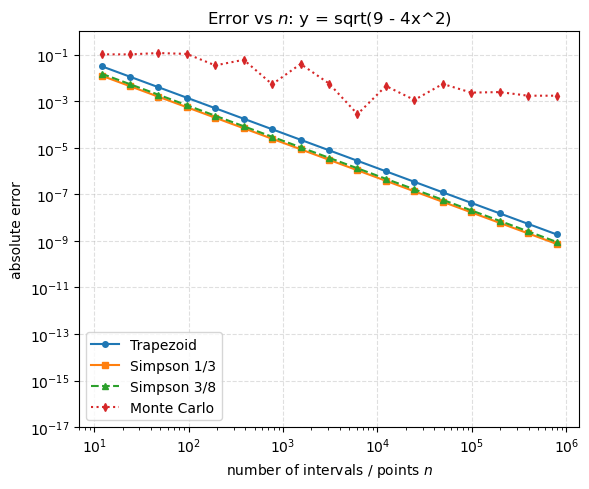

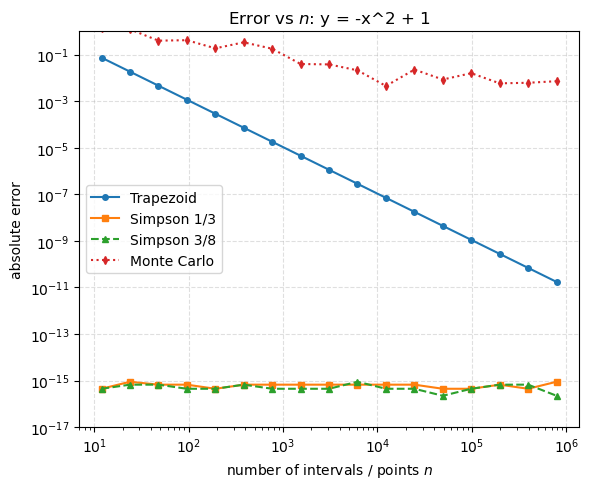

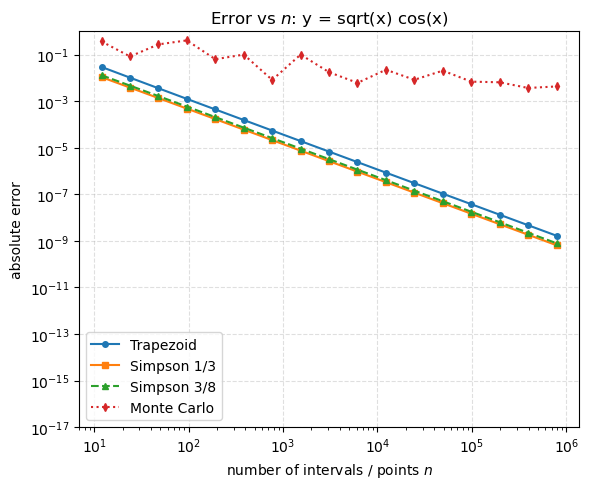

In [5]:
# n = 12, 24, 48, ... (always divisible by 2 and 3, so all rules use the same n)
ns = [6*2**k for k in range(1, 18)]
floor = 1e-17    # errors of exactly 0 cannot be drawn on a log axis, so raise them to this

for i, (f, a, b, name) in enumerate(tests, start=1):
    exact, _ = quad(f, a, b)

    errors = {"Trapezoid": [], "Simpson 1/3": [], "Simpson 3/8": [], "Monte Carlo": []}
    for n in ns:
        errors["Trapezoid"].append(abs(trapezoid(f, a, b, n)[0] - exact))
        errors["Simpson 1/3"].append(abs(simpson13(f, a, b, n)[0] - exact))
        errors["Simpson 3/8"].append(abs(simpson38(f, a, b, n)[0] - exact))
        errors["Monte Carlo"].append(abs(montecarlo(f, a, b, n, seed=n)[0] - exact))

    plt.figure(figsize=(6, 5))
    styles = ["o-", "s-", "^--", "d:"]
    for (method, err), style in zip(errors.items(), styles):
        plt.loglog(ns, np.maximum(err, floor), style, markersize=4, label=method)
    plt.xlabel("number of intervals / points $n$")
    plt.ylabel("absolute error")
    plt.title(f"Error vs $n$: {name}")
    plt.ylim(1e-17, 1)
    plt.grid(True, which="major", linestyle="--", alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"11-error-{i}.png", dpi=150)
    plt.show()

**Figures 4-6 (Monte Carlo points).** Throw random points in a box that holds the curve and the x-axis. Blue points are between the curve and the axis above it, red points are between the curve and the axis below it. Area = box area $\times$ (number of points in the region)/(total points). Integral = blue minus red, area = blue plus red.

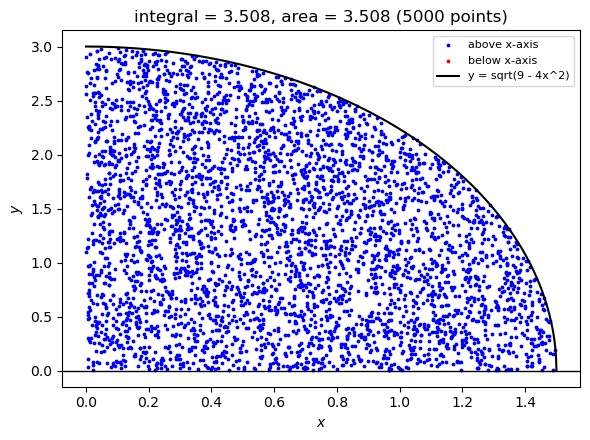

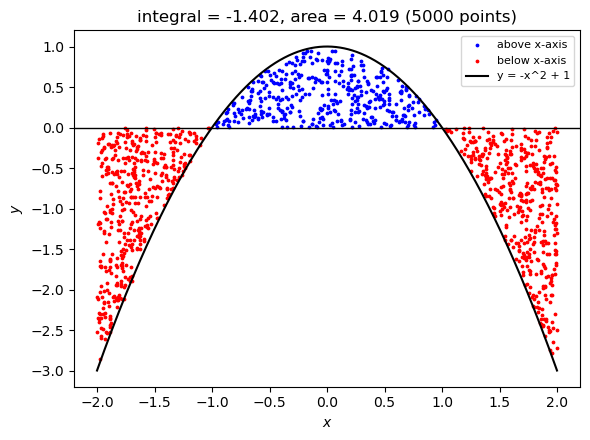

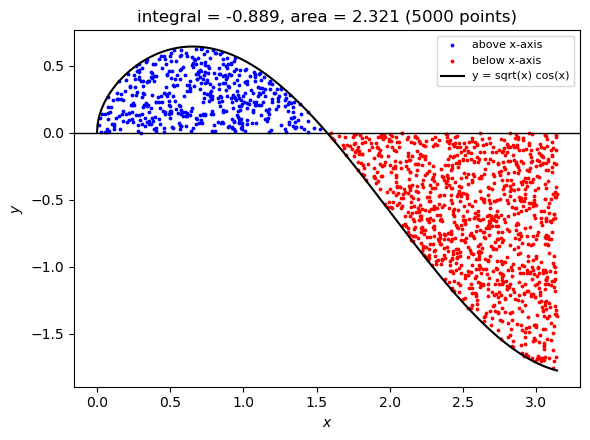

In [6]:
# hit-or-miss Monte Carlo: scatter random points over a bounding box, then keep
# only the ones trapped between the curve and the x-axis
rng = np.random.default_rng(2024)
n_points = 5000

def hit_or_miss(f, a, b, n, rng):
    """Return the sampled points, the blue/red masks, the signed integral and the total area."""
    curve_x = np.linspace(a, b, 1000)
    curve_y = f(curve_x)
    y_low, y_high = min(0, curve_y.min()), max(0, curve_y.max())
    box = (b - a)*(y_high - y_low)

    px = rng.uniform(a, b, n)
    py = rng.uniform(y_low, y_high, n)
    fp = f(px)

    # a point is trapped when it lies between 0 and f(px); the sign of py tells the color
    blue = (py >= 0) & (py <= fp)
    red = (py < 0) & (py >= fp)

    # every point carries box/n of area
    return (px, py, curve_x, curve_y, blue, red,
            box*(blue.sum() - red.sum())/n, box*(blue.sum() + red.sum())/n)

for i, (f, a, b, name) in enumerate(tests, start=1):
    px, py, cx, cy, blue, red, integral, area = hit_or_miss(f, a, b, n_points, rng)

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(px[blue], py[blue], s=3, color="blue", label="above x-axis")
    ax.scatter(px[red], py[red], s=3, color="red", label="below x-axis")
    ax.plot(cx, cy, "k-", label=name)
    ax.axhline(0, color="k", linewidth=1)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_title(f"integral = {integral:.3f}, area = {area:.3f} ({n_points} points)")
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(f"11-mc-{i}.png", dpi=150)
    plt.show()

### Problem code summary

Include a brief summary (2-3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* This script compares four ways of integrating the same three curves (trapezoid, Simpson 1/3, Simpson 3/8 and Monte Carlo) against `scipy.integrate.quad`. I wrote each Newton-Cotes rule as a single weighted sum with NumPy slices so there are no Python loops, and I got the total area by passing $|f|$ through the same rule so the two outputs never disagree. The intervals follow $n = 6\cdot 2^k$ so one grid works for both Simpson rules, Monte Carlo uses the mean value method for the error study, and the colored plots use a hit-or-miss helper so the integral and the area come from the same set of points.